# Анализ воронки, RFM-сегментов и ресторанов сервиса доставки

С данными сервиса доставки еды «Всё.из.кафе» вы уже работали в одном из проектов базового курса. Тогда вы описывали ключевые метрики продукта — количество пользователей, заказов и выручку.

Однако конкуренты сервиса не дремлют, и руководство ждёт от продукта роста. Найти инсайты, которые позволят сервису повысить показатель удержания пользователей и улучшить взаимодействие с партнёрами, поручено продуктовому аналитику, то есть вам.

Вам необходимо помочь бизнесу ответить на следующие вопросы:
- Как ведут себя пользователи? Как наиболее эффективно выстроить работу с ними, чтобы они продолжали пользоваться продуктом?
- Какой путь проходят пользователи в сервисе? Где «проваливаются»?
- Как улучшить взаимодействие с партнёрами-ресторанами?

### Задачи 

В рамках данного проекта вы проведёте комплексный анализ данных:
- изучите пользовательский путь и проанализируете конверсии через воронки;
- сегментируете пользователей с помощью RFM-модели для оценки лояльности и поведения клиентов;
- кластеризуете рестораны методом K-Means, чтобы выделить группы с разными моделями работы и разработать персонализированные маркетинговые стратегии.

Такой подход позволит ближе познакомиться с работой сервиса, выявить узкие места и предложить решения для удержания пользователей и повышения эффективности сотрудничества с ресторанами.


### Данные

Данные включают следующие сведения:
      
- `visitor_uuid` — идентификатор посетителя. Это идентификатор, который присваивается системой любому новому пользователю вне зависимости от того, зарегистрировался он в продукте или нет.
- `user_id` — идентификатор зарегистрированного пользователя. Присваивается посетителю после создания учётной записи: ввода логина, пароля, адреса доставки и контактных данных.
- `device_type` — тип платформы, с которой посетитель зашёл в продукт.
- `city_id` — город, из которого посетитель зашёл в сервис.
- `source` — рекламный источник привлечения посетителя.
- `first_date` — дата первого посещения продукта.
- `visit_id` — уникальный идентификатор сессии.
- `event` — название аналитического события.
- `datetime` — дата и время события.
- `rest_id` — уникальный идентификатор ресторана (заполняется для заказов, карточек ресторанов и блюд).
- `object_id` — уникальный идентификатор блюда (заполняется для заказов и карточек блюд).
- `order_id` — уникальный идентификатор заказа.
- `revenue` — выручка от заказа (в рублях). Это та сумма, которую пользователь видит при оплате.
- `delivery` — стоимость доставки (в рублях).
- `commission` — комиссия, которую «Всё.из.кафе» берёт с выручки ресторана, в процентах.

    
### План проекта
- Загрузка данных и их предобработка.
- Анализ пользовательского пути новых пользователей.
- RFM сегментация.
- K-Means кластеризация.
- Итоговый вывод и рекомендации.

## 1. Загрузка данных и их предобработка

Загрузите данные и получите первую информацию о них. Проведите необходимую предобработку. Основную информацию о данных и этапы предобработки зафиксируйте в кратком промежуточном выводе.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

In [2]:
# Сначала используем локальный файл, а на платформе — ссылку на датасет
local_path = 'insides_data.csv'
data_url = 'https://code.s3.yandex.net/datasets/insides_data.csv'

try:
    data = pd.read_csv(local_path)
except FileNotFoundError:
    data = pd.read_csv(data_url)

display(data.head())
data.info()

,visitor_uuid,user_id,device_type,city_id,source,first_date,visit_id,event,datetime,rest_id,object_id,order_id,revenue,delivery,commission
0,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,authorization,2021-05-01 16:07:53,NaN,NaN,NaN,NaN,NaN,NaN
1,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,reg_page,2021-05-01 16:09:16,NaN,NaN,NaN,NaN,NaN,NaN
2,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,confirm_phone,2021-05-01 16:09:19,NaN,NaN,NaN,NaN,NaN,NaN
3,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,login,2021-05-01 16:09:23,NaN,NaN,NaN,NaN,NaN,NaN
4,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,main_page,2021-05-01 16:09:34,2c6095730b514c189ee41c65f03febc3,NaN,NaN,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205510 entries, 0 to 205509
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   visitor_uuid  205510 non-null  object 
 1   user_id       205510 non-null  float64
 2   device_type   205510 non-null  object 
 3   city_id       205510 non-null  int64  
 4   source        205510 non-null  object 
 5   first_date    205510 non-null  object 
 6   visit_id      205510 non-null  int64  
 7   event         205510 non-null  object 
 8   datetime      205510 non-null  object 
 9   rest_id       166915 non-null  object 
 10  object_id     21308 non-null   float64
 11  order_id      7008 non-null    float64
 12  revenue       7008 non-null    float64
 13  delivery      7008 non-null    float64
 14  commission    21308 non-null   float64
dtypes: float64(6), int64(2), object(7)
memory usage: 23.5+ MB


In [3]:
print('Размер таблицы:', data.shape)
print('Количество полных дубликатов:', data.duplicated().sum())
display(data.isna().sum().to_frame('missing_values'))

data['first_date'] = pd.to_datetime(data['first_date'])
data['datetime'] = pd.to_datetime(data['datetime'])

print('Период первых посещений:', data['first_date'].min(), '—', data['first_date'].max())
print('Период событий:', data['datetime'].min(), '—', data['datetime'].max())
display(data[['device_type', 'event']].describe())

Размер таблицы: (205510, 15)
Количество полных дубликатов: 0


,missing_values
visitor_uuid,0
user_id,0
device_type,0
city_id,0
source,0
first_date,0
visit_id,0
event,0
datetime,0
rest_id,38595


Период первых посещений: 2021-04-30 00:00:00 — 2021-07-01 00:00:00
Период событий: 2021-05-01 00:10:55 — 2021-07-02 00:12:08


,device_type,event
count,205510,205510
unique,2,8
top,Desktop,main_page
freq,159119,145607


### Промежуточный вывод

В датасете 205 510 строк и 15 столбцов. Полных дубликатов нет. Данные охватывают первые посещения с 30 апреля по 1 июля 2021 года и события с 1 мая по 2 июля 2021 года. Столбцы `first_date` и `datetime` приведены к типу даты и времени.

Пропуски встречаются только в полях, которые заполняются для определённых событий: сведения о ресторане, блюде, заказе, выручке, доставке и комиссии. Поэтому удалять такие строки не требуется. Для дальнейших расчётов будут использоваться только подходящие события и заполненные для них показатели.

---

## 2. Анализ пользовательского пути

Маркетологи стали замечать следующее: деньги на рекламу по-прежнему тратятся, а заказов стало меньше. И это несмотря на то, что приложение скачивается и устанавливается так же активно, как раньше. Складывается ощущение, что пользователи где-то теряются. При этом доля заказов с десктопной версии приложения увеличилась по сравнению с мобильной.

Разработчики говорят, что последние обновления мобильной версии приложения не должны были повлиять на каталог блюд или его выбор для заказа и последующей оплаты доставки, так как изменения касались нового алгоритма подтверждения мобильного телефона и адреса доставки.

С помощью воронок изучите общий пользовательский путь новых пользователей, затем сравните поведение пользователей мобильной и десктопной версий приложения. 

**Задача 2.1.** Постройте и визуализируйте общую воронку (по всем данным), затем опишите пользовательский путь: какие этапы представлены, какова их последовательность, на каком (или на каких) этапах теряется большая часть новых пользователей.
    
При решении постройте две воронки: 
- **классическую воронку** — доля от первого шага в процентах
- **step-by-step** — с конверсией от предыдущего этапа.

Предполагается, что пользователь проходит такой путь к оформлению доставки блюда из ресторанов:
1. `authorization` — авторизация пользователя — запуск приложения.
2. `main_page` — загрузка основной страницы приложения.
2. `reg_page` — переход на страницу регистрации.
2. `confirm_phone` — подтверждение телефона (окончание процесса регистрации).
2. `object_page` — страница блюда.
2. `add_to_cart` — переход в корзину.
2. `order` — оформление заказа.    

In [4]:
# Порядок этапов пользовательского пути
funnel_steps = [
    'authorization', 'main_page', 'reg_page', 'confirm_phone',
    'object_page', 'add_to_cart', 'order'
]

funnel = data[data['event'].isin(funnel_steps)]
funnel = funnel.groupby('event')['visitor_uuid'].nunique()
funnel = funnel.reindex(funnel_steps).reset_index()
funnel.columns = ['event', 'users']

funnel['classic_conversion'] = funnel['users'] / funnel.loc[0, 'users'] * 100
funnel['step_conversion'] = funnel['users'] / funnel['users'].shift(1) * 100
funnel.loc[0, 'step_conversion'] = 100
display(funnel.round(2))

,event,users,classic_conversion,step_conversion
0,authorization,7796,100.00,100.00
1,main_page,6835,87.67,87.67
2,reg_page,5649,72.46,82.65
3,confirm_phone,4347,55.76,76.95
4,object_page,3530,45.28,81.21
5,add_to_cart,2929,37.57,82.97
6,order,2432,31.20,83.03


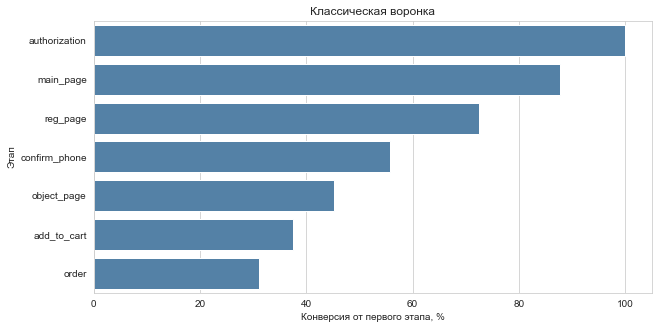

In [5]:
plt.figure(figsize=(10, 5))
sns.barplot(data=funnel, x='classic_conversion', y='event', color='steelblue')
plt.title('Классическая воронка')
plt.xlabel('Конверсия от первого этапа, %')
plt.ylabel('Этап')
plt.xlim(0, 105)
plt.show()

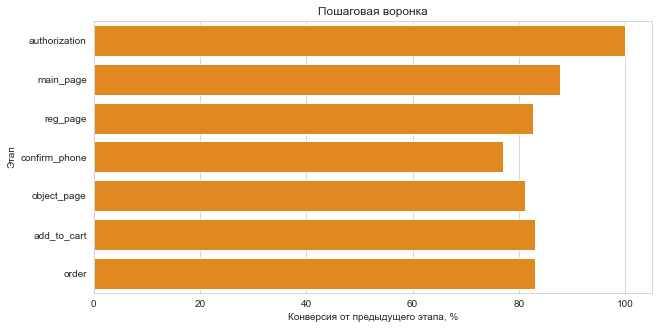

In [6]:
plt.figure(figsize=(10, 5))
sns.barplot(data=funnel, x='step_conversion', y='event', color='darkorange')
plt.title('Пошаговая воронка')
plt.xlabel('Конверсия от предыдущего этапа, %')
plt.ylabel('Этап')
plt.xlim(0, 105)
plt.show()

### Промежуточный вывод

В начале воронки находятся 7 796 новых посетителей. До главной страницы доходит 87,7% пользователей, до регистрации — 72,5%, телефон подтверждают 55,8%, страницу блюда открывают 45,3%, в корзину переходят 37,6%, а заказ оформляют 31,2%.

Наибольшая относительная потеря происходит при переходе от страницы регистрации к подтверждению телефона: пошаговая конверсия составляет 77,0%. Исходя из этого можно выдвинуть предположение о проблемах с подтверждением телефона (например, медленно приходящие смс или проблемы с иностранными номерами телефонов) На остальных этапах пошаговая конверсия находится примерно на уровне 81–88%.

**Задача 2.2.** Сравните пользовательский путь в двух приложениях: в мобильной версии и десктопной. Для этого постройте и визуализируйте **две воронки step-by-step**: для новых пользователей **мобильной** и **десктопной** версий приложения.
    
Сравните результаты между собой и проанализируйте, есть ли различия в пользовательском пути для различных приложений. Результаты сравнения опишите в небольшом **промежуточном выводе**.

In [7]:
# Число уникальных посетителей на этапах по типу устройства
device_funnel = data[data['event'].isin(funnel_steps)]
device_funnel = device_funnel.groupby(['device_type', 'event'])['visitor_uuid'].nunique()
device_funnel = device_funnel.unstack(fill_value=0)
device_funnel = device_funnel.reindex(columns=funnel_steps)
display(device_funnel)

event,authorization,main_page,reg_page,confirm_phone,object_page,add_to_cart,order
device_type,,,,,,,
Desktop,4938,4463,3546,3197,2709,2217,1821
Mobile,2858,2372,2103,1150,821,712,611


In [8]:
device_step_conversion = device_funnel.div(device_funnel.shift(axis=1)) * 100
device_step_conversion[funnel_steps[0]] = 100
device_step_conversion = device_step_conversion[funnel_steps]
display(device_step_conversion.round(2))

event,authorization,main_page,reg_page,confirm_phone,object_page,add_to_cart,order
device_type,,,,,,,
Desktop,100,90.38,79.45,90.16,84.74,81.84,82.14
Mobile,100,83.00,88.66,54.68,71.39,86.72,85.81


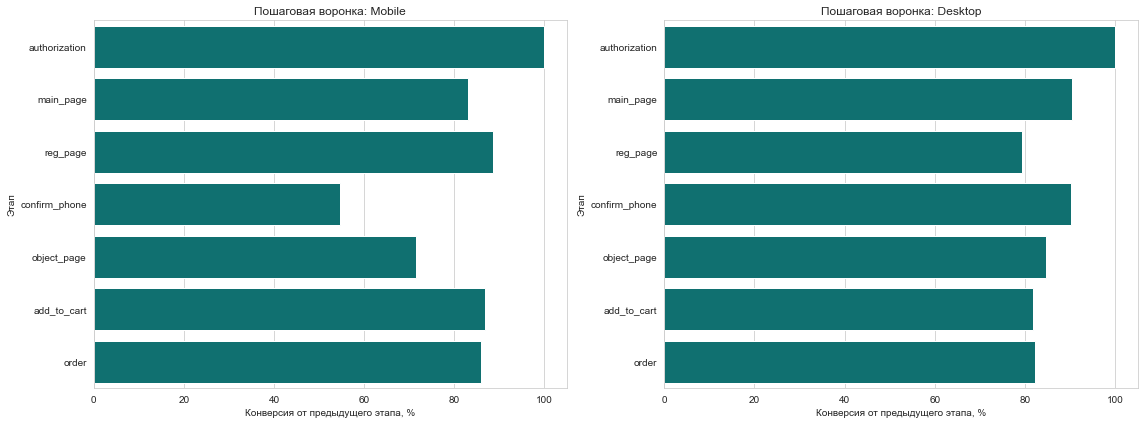

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)

for ax, device in zip(axes, ['Mobile', 'Desktop']):
    values = device_step_conversion.loc[device]
    sns.barplot(x=values.values, y=values.index, ax=ax, color='teal')
    ax.set_title(f'Пошаговая воронка: {device}')
    ax.set_xlabel('Конверсия от предыдущего этапа, %')
    ax.set_ylabel('Этап')
    ax.set_xlim(0, 105)

plt.tight_layout()
plt.show()

### Промежуточный вывод

Пути пользователей заметно различаются. В десктопной версии от регистрации к подтверждению телефона переходит 90,2% пользователей, а в мобильной — только 54,7%. После подтверждения телефона мобильная версия также уступает десктопной на переходе к странице блюда: 71,4% против 84,7%.

При этом на последних этапах мобильные пользователи конвертируются немного лучше: из карточки блюда в корзину переходят 86,7% против 81,8% на десктопе, а из корзины в заказ — 85,8% против 82,1%. Следовательно, основная проблема мобильного приложения возникает не при выборе блюда и оплате, а раньше — прежде всего на этапе подтверждения телефона, что согласуется с результатами общей конверсии. Следует проверить, есть ли проблемы с подтверждением номера телефона в мобильной версии.


---

## 3. RFM сегментация

У сервиса доставки еды не такое высокое удержание пользователей: в первый день возвращается около 14% посетителей, а на седьмой день и того меньше — около 4–5%. Маркетологи хотят запустить несколько рекламных кампаний, направленных на удержание платящих пользователей и их возврат в сервис, если они давно не совершали заказы.

Для этого необходимо сегментировать пользователей на различные поведенческие сегменты с помощью RFM-сегментации по трём показателям: 
- **давность** (Recency), 
- **частота покупок** (Frequency), 
- **сумма трат** (Monetary).

В качестве даты анализа установите **03 июля 2021 года**.

**Задача 3.1.** Для каждого покупателя посчитайте:
- количество дней с последней покупки — давность (R);
- частоту покупок (F);
- стоимость всех покупок — сумму трат (M).
    
В качестве даты анализа установите **03 июля 2021 года**. После этого постройте три гистограммы и проанализируйте их.

In [10]:
# Для расчётов используем только завершённые заказы
orders = data[data['event'] == 'order'].copy()

print('Строк с заказами:', len(orders))
print('Уникальных заказов:', orders['order_id'].nunique())
print('Покупателей:', orders['user_id'].nunique())
print('Заказов без идентификатора:', orders['order_id'].isna().sum())

Строк с заказами: 3549
Уникальных заказов: 3549
Покупателей: 2416
Заказов без идентификатора: 0


In [11]:
analysis_date = pd.Timestamp('2021-07-03')

rfm = orders.groupby('user_id').agg(
    last_order=('datetime', 'max'),
    frequency=('order_id', 'nunique'),
    monetary=('revenue', 'sum')
).reset_index()

rfm['recency'] = (analysis_date - rfm['last_order'].dt.normalize()).dt.days
rfm = rfm[['user_id', 'recency', 'frequency', 'monetary']]
display(rfm.head())
display(rfm[['recency', 'frequency', 'monetary']].describe())

,user_id,recency,frequency,monetary
0,5506.0,33,2,3752.00
1,6291.0,58,1,1750.00
2,6820.0,42,1,1260.14
3,11062.0,58,1,3785.60
4,13254.0,55,1,553.00


,recency,frequency,monetary
count,2416.000000,2416.000000,2416.000000
mean,32.086093,1.468957,3720.171429
std,17.444239,0.950901,4036.352731
min,1.000000,1.000000,235.200000
25%,18.000000,1.000000,1512.000000
50%,30.000000,1.000000,2590.000000
75%,47.000000,2.000000,4443.117000
max,63.000000,12.000000,81690.000000


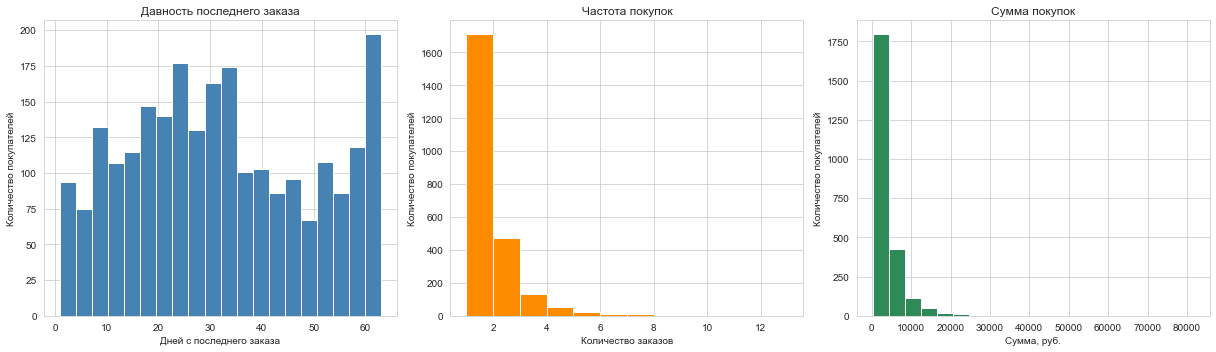

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].hist(rfm['recency'], bins=20, color='steelblue', edgecolor='white')
axes[0].set_title('Давность последнего заказа')
axes[0].set_xlabel('Дней с последнего заказа')
axes[0].set_ylabel('Количество покупателей')

axes[1].hist(rfm['frequency'], bins=range(1, rfm['frequency'].max() + 2), color='darkorange', edgecolor='white')
axes[1].set_title('Частота покупок')
axes[1].set_xlabel('Количество заказов')
axes[1].set_ylabel('Количество покупателей')

axes[2].hist(rfm['monetary'], bins=20, color='seagreen', edgecolor='white')
axes[2].set_title('Сумма покупок')
axes[2].set_xlabel('Сумма, руб.')
axes[2].set_ylabel('Количество покупателей')

plt.tight_layout()
plt.show()

### Промежуточный вывод

В анализ вошли 2 416 покупателей. Давность последней покупки составляет от 1 до 63 дней, медианное значение — 30 дней. Распределение давности достаточно широкое: в данных есть как недавно активные пользователи, так и покупатели, которые не возвращались около двух месяцев.

Частота заказов сильно смещена к минимальным значениям. Один заказ совершили 1 709 покупателей, или 70,7%; два заказа — 473 пользователя; три и более — только 234 пользователя, или 9,7%. Сумма покупок также имеет правый хвост: медиана равна 2 590 рублям при среднем значении 3 720 рублей, а максимальная сумма достигает 81 690 рублей. Это указывает на небольшую группу покупателей с заметно более высокими тратами - так называемых "китов".


**Задача 3.2.** Выделите **RFM-сегменты** и изучите распределение пользователей по ним.
    
Примените следующие подходы к выделению RFM сегментов:
- **Recency** — разделите на три равные группы.
- **Frequency** —  разделите на три группы: 
    - пользователи с 1 заказом (F-сегмент с небольшим количеством заказов);
    - пользователи с 2 заказами (F-сегмент со средним количеством заказов);
    - пользователи с 3 и более заказами (F-сегмент с большим количеством заказов).
- **Monetary** — разделите на три группы по 33-му и 66-му перцентилям.
    
После этого посчитайте количество покупателей в каждом сегменте, сделайте промежуточные выводы и напишите рекомендации.

In [13]:
# R делим на три равные по численности группы
rfm['r_score'] = pd.qcut(
    rfm['recency'].rank(method='first'),
    q=3,
    labels=[3, 2, 1]
).astype(int)

rfm['f_score'] = np.select(
    [rfm['frequency'] == 1, rfm['frequency'] == 2, rfm['frequency'] >= 3],
    [1, 2, 3]
).astype(int)

In [14]:
m_33 = rfm['monetary'].quantile(0.33)
m_66 = rfm['monetary'].quantile(0.66)

rfm['m_score'] = np.select(
    [rfm['monetary'] <= m_33, rfm['monetary'] <= m_66],
    [1, 2],
    default=3
).astype(int)

rfm['rfm_segment'] = (
    rfm['r_score'].astype(str)
    + rfm['f_score'].astype(str)
    + rfm['m_score'].astype(str)
)

print('33-й перцентиль Monetary:', round(m_33, 2))
print('66-й перцентиль Monetary:', round(m_66, 2))
display(rfm.head())

33-й перцентиль Monetary: 1764.0
66-й перцентиль Monetary: 3583.86


,user_id,recency,frequency,monetary,r_score,f_score,m_score,rfm_segment
0,5506.0,33,2,3752.00,2,2,3,223
1,6291.0,58,1,1750.00,1,1,1,111
2,6820.0,42,1,1260.14,1,1,1,111
3,11062.0,58,1,3785.60,1,1,3,113
4,13254.0,55,1,553.00,1,1,1,111


,rfm_segment,users,share
0,111,267,11.05
1,112,232,9.60
2,113,94,3.89
3,121,16,0.66
4,122,48,1.99
5,123,90,3.73
6,132,7,0.29
7,133,51,2.11
8,211,247,10.22
9,212,197,8.15


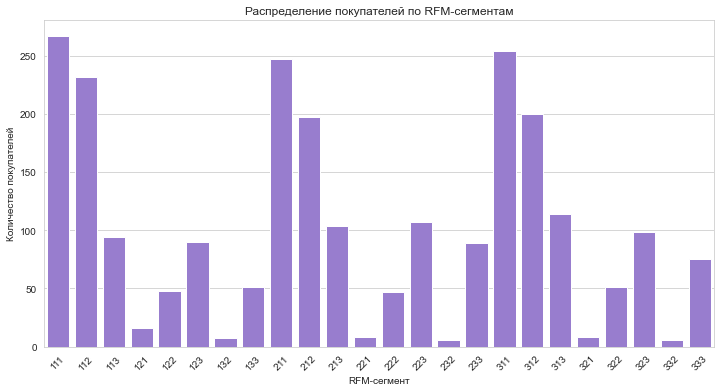

In [15]:
segment_counts = rfm['rfm_segment'].value_counts().sort_index().reset_index()
segment_counts.columns = ['rfm_segment', 'users']
segment_counts['share'] = segment_counts['users'] / len(rfm) * 100
display(segment_counts.round(2))

plt.figure(figsize=(12, 6))
sns.barplot(data=segment_counts, x='rfm_segment', y='users', color='mediumpurple')
plt.title('Распределение покупателей по RFM-сегментам')
plt.xlabel('RFM-сегмент')
plt.ylabel('Количество покупателей')
plt.xticks(rotation=45)
plt.show()

### Промежуточный вывод и рекомендации

По давности покупатели разделены на три почти равные группы: недавние покупки — 1–22 дня, средняя давность — 22–40 дней, давние покупки — 40–63 дня. Границы Monetary составили 1 764 рубля и 3 583,86 рубля. Самые крупные полные сегменты — `111` (267 покупателей), `311` (254), `112` (232) и`312` (200). Во всех этих группах пользователи совершили только один заказ, поэтому основной резерв роста связан с повторной покупкой, однако больше перспектив в сегментах `112` и `312` так как их средний чек больше.

Для недавно активных сегментов `311`–`313` стоит запустить коммуникацию, стимулирующую второй заказ: персональную подборку ресторанов, ограниченный по времени промокод или бесплатную доставку. Сегменты `323` и `333` следует удерживать программой лояльности и персональными предложениями, поскольку они покупают чаще и тратят больше. Для давно неактивных клиентов `111`–`113` нужна отдельная реактивационная кампания; её эффективность следует оценивать на тестовой группе, чтобы не расходовать бюджет на пользователей с низкой вероятностью возврата.

---

## 4. K-Means кластеризация

Чтобы лучше понимать поведение ресторанов и предлагать им персонализированные условия сотрудничества, а также создавать персонализированные предложения для пользователей, маркетологи запросили кластеризацию ресторанов по следующим параметрам:
- общее количество заказов;
- средняя стоимость заказа;
- общее число заказанных уникальных блюд (ассортимент ресторана).

С помощью метода K-Means разделите рестораны на кластеры, отражающие различные модели работы и целевые сегменты. Это позволяет выделить группы ресторанов с похожими характеристиками и разрабатывать для них эффективные маркетинговые стратегии.

**Задача 4.1.** Подготовьте данные для кластеризации и для каждого ресторана подсчитайте:
- общее количество заказов;
- средняя стоимость заказа;
- общее число заказанных уникальных блюд (ассортимент ресторана).

In [16]:
restaurant_metrics = orders.groupby('rest_id').agg(
    orders_count=('order_id', 'nunique'),
    average_order_value=('revenue', 'mean'),
    unique_dishes=('object_id', 'nunique')
).reset_index()

display(restaurant_metrics.head())

,rest_id,orders_count,average_order_value,unique_dishes
0,1be5a933aab34fbab594bebba48e976e,144,2260.180222,28
1,1d6bb74687104fa1953924c9684fe624,108,2959.256481,19
2,2c6095730b514c189ee41c65f03febc3,8,1673.000000,4
3,3247a3b5f9494812a3c1a73c5b61f004,33,2777.209697,4
4,39b7eab4f4704ed2886fafe171489960,33,2011.269697,5


In [17]:
print('Количество ресторанов:', restaurant_metrics['rest_id'].nunique())
print('Пропуски в признаках:')
display(restaurant_metrics.isna().sum().to_frame('missing_values'))
display(restaurant_metrics.drop(columns='rest_id').describe())

Количество ресторанов: 21
Пропуски в признаках:


,missing_values
rest_id,0
orders_count,0
average_order_value,0
unique_dishes,0


,orders_count,average_order_value,unique_dishes
count,21.000000,21.000000,21.000000
mean,169.000000,2557.595053,15.285714
std,315.844899,900.370846,23.698403
min,5.000000,1507.735289,1.000000
25%,23.000000,1874.545455,4.000000
50%,77.000000,2369.043478,6.000000
75%,135.000000,2959.256481,13.000000
max,1199.000000,4754.400000,91.000000


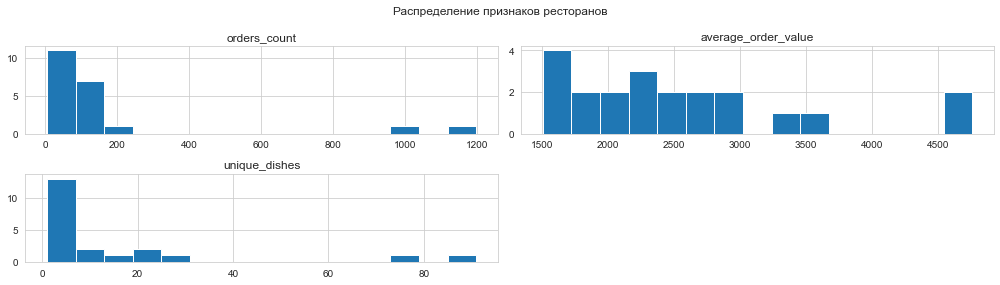

In [18]:
restaurant_metrics.hist(figsize=(14, 4), bins=15, edgecolor='white')
plt.suptitle('Распределение признаков ресторанов')
plt.tight_layout()
plt.show()

**Задача 4.2.** Нормализуйте данные и найдите оптимальное количество кластеров, использовав метод `.inertia_`. Постройте график зависимости инерции от числа кластеров (метод «локтя») и предположите оптимальное количество кластеров.

In [19]:
features = restaurant_metrics[[
    'orders_count', 'average_order_value', 'unique_dishes'
]]

scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

In [20]:
cluster_range = range(1, 11)
inertia = []

for cluster_count in cluster_range:
    model = KMeans(n_clusters=cluster_count, random_state=42, n_init=10)
    model.fit(features_scaled)
    inertia.append(model.inertia_)

inertia_table = pd.DataFrame({
    'clusters': list(cluster_range),
    'inertia': inertia
})
display(inertia_table.round(2))

,clusters,inertia
0,1,63.00
1,2,23.87
2,3,9.31
3,4,5.03
4,5,3.60
5,6,2.15
6,7,1.63
7,8,1.21
8,9,0.97
9,10,0.78


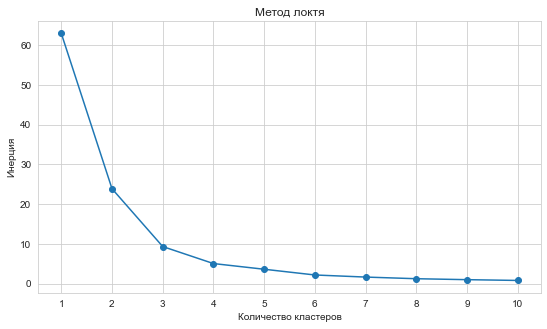

In [21]:
plt.figure(figsize=(9, 5))
plt.plot(inertia_table['clusters'], inertia_table['inertia'], marker='o')
plt.title('Метод локтя')
plt.xlabel('Количество кластеров')
plt.ylabel('Инерция')
plt.xticks(list(cluster_range))
plt.show()

### Выбор количества кластеров

Инерция быстро снижается с 63,0 для одного кластера до 23,87 для двух и 9,31 для трёх. После трёх кластеров снижение становится заметно более плавным. Поэтому точка локтя соответствует трём кластерам; это значение используется в итоговой модели.

**Задача 4.3.** Проведите кластеризацию, проанализируйте полученные результаты и рассчитайте средние значения по каждому кластеру.
    
После этого визуализируйте результаты, чтобы проследить зависимость признаков друг от друга. Постройте две визуализации, на которые нанесите все кластеры:
- средний чек в зависимости от количества заказов;
- количество блюд в зависимости от количества заказов.

После этого опишите каждый кластер в промежуточном выводе. 

In [22]:
# По графику локтя выбираем три кластера
optimal_clusters = 3
final_model = KMeans(
    n_clusters=optimal_clusters,
    random_state=42,
    n_init=10
)
restaurant_metrics['cluster'] = final_model.fit_predict(features_scaled)
display(restaurant_metrics.head())

,rest_id,orders_count,average_order_value,unique_dishes,cluster
0,1be5a933aab34fbab594bebba48e976e,144,2260.180222,28,0
1,1d6bb74687104fa1953924c9684fe624,108,2959.256481,19,0
2,2c6095730b514c189ee41c65f03febc3,8,1673.000000,4,0
3,3247a3b5f9494812a3c1a73c5b61f004,33,2777.209697,4,0
4,39b7eab4f4704ed2886fafe171489960,33,2011.269697,5,0


In [23]:
cluster_summary = restaurant_metrics.groupby('cluster').agg(
    restaurants=('rest_id', 'count'),
    orders_count=('orders_count', 'mean'),
    average_order_value=('average_order_value', 'mean'),
    unique_dishes=('unique_dishes', 'mean')
).round(2)

display(cluster_summary)

,restaurants,orders_count,average_order_value,unique_dishes
cluster,,,,
0,15,69.60,2167.86,9.0
1,2,1100.00,2498.83,83.0
2,4,76.25,4048.50,5.0


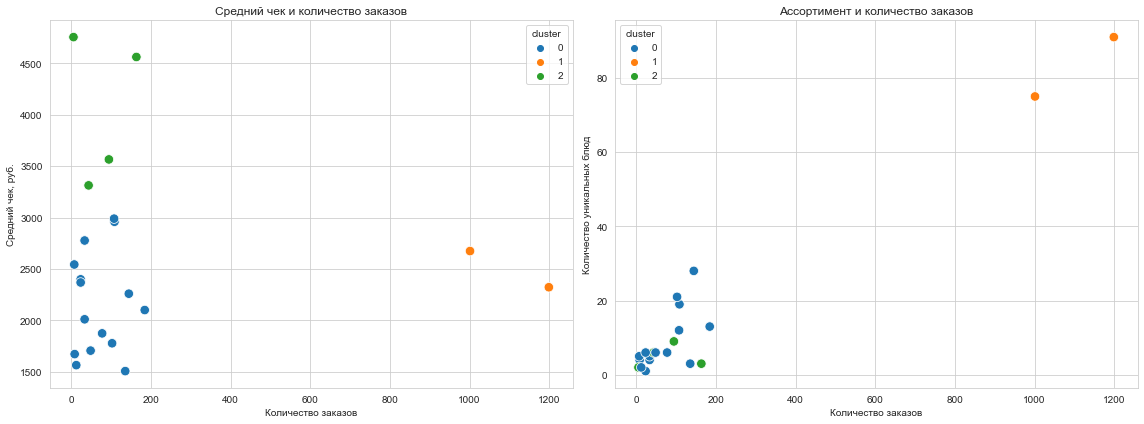

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    data=restaurant_metrics,
    x='orders_count',
    y='average_order_value',
    hue='cluster',
    palette='tab10',
    s=90,
    ax=axes[0]
)
axes[0].set_title('Средний чек и количество заказов')
axes[0].set_xlabel('Количество заказов')
axes[0].set_ylabel('Средний чек, руб.')

sns.scatterplot(
    data=restaurant_metrics,
    x='orders_count',
    y='unique_dishes',
    hue='cluster',
    palette='tab10',
    s=90,
    ax=axes[1]
)
axes[1].set_title('Ассортимент и количество заказов')
axes[1].set_xlabel('Количество заказов')
axes[1].set_ylabel('Количество уникальных блюд')

plt.tight_layout()
plt.show()

### Промежуточный вывод

Кластер 0 — основная группа из 15 ресторанов. В среднем у них 69,6 заказа, средний чек 2 167,86 рубля и ассортимент из 9 заказанных блюд. Это рестораны с умеренной или низкой активностью и средним ценовым уровнем. Им подойдут инструменты роста числа заказов: продвижение популярных блюд, участие в общих акциях и улучшение видимости в каталоге.

Кластер 1 включает два ресторана-лидера. В среднем на ресторан приходится 1 100 заказов, средний чек составляет 2 498,83 рубля, а ассортимент — 83 блюда. Для них важнее поддерживать качество и доступность широкого меню, обеспечивать стабильную операционную работу и предлагать индивидуальные условия сотрудничества.

Кластер 2 состоит из четырёх ресторанов с высоким средним чеком — 4 048,50 рубля. При этом среднее число заказов равно 76,25, а ассортимент ограничен пятью блюдами. Эти рестораны можно позиционировать как премиальные и продвигать среди пользователей с высоким Monetary; дополнительно стоит проверить, сможет ли осторожное расширение ассортимента увеличить частоту заказов.

## 5. Итоговый вывод и рекомендации


### Итоговый вывод

Анализ показал, что ключевая потеря новых пользователей связана с мобильной регистрацией. В общей воронке до заказа доходит 31,2% посетителей, а самая низкая пошаговая конверсия наблюдается между регистрацией и подтверждением телефона — 77,0%. На мобильных устройствах этот переход проходят только 54,7% пользователей против 90,2% на десктопе. После прохождения регистрации мобильная аудитория успешно движется к заказу, стоит разобраться, что мешает пользователям мобильной версии завершить подтвердить номер телефона и завершить регистрацию.

RFM-анализ охватил 2 416 покупателей. Большинство из них не формируют устойчивую привычку: 70,7% сделали только один заказ, а три заказа и более совершили 9,7%. Для увеличения удержания следует стимулировать второй заказ у недавно привлечённых покупателей, особенно тех, чей средний чек держится на среднем и высоком уровнях, отдельно возвращать давно неактивных клиентов, но делать это аккуратно, возможно, в тестовом формате, и защищать небольшую группу частых покупателей с высокими тратами с помощью программы лояльности и персональных предложений. Эффективность кампаний необходимо проверять экспериментально по повторной конверсии и дополнительной выручке.

Рестораны разделены на три содержательных кластера. Основную группу составляют 15 заведений с умеренным числом заказов и средним чеком - такие рестораны следкет продвигать среди клиентов которые закзывают часто, но на небольшие суммы, а так же стимулировать их расширять меню. Два ресторана-лидера отличаются очень большим объёмом заказов и широким ассортиментом — им нужны индивидуальные условия и поддержка стабильной работы, возможно, стои разработать персонализированные предложения, чтобы свести к минимуму шанс из ухода к конкурентам. Ещё четыре ресторана имеют высокий средний чек и небольшой ассортимент - их целесообразно продвигать среди покупателей с высоким средним чеком и обсудить с ними расширение ассортимента на доставку.

Приоритеты для продукта: устранить мобильный провал при подтверждении телефона, повысить долю второго заказа персональными механиками удержания и выстроить разные программы сотрудничества для трёх типов ресторанов.